# Importing Libraries

In [56]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# PCA
from sklearn.decomposition import PCA

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Forecasting Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Prophet
from prophet import Prophet

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

# Load data

In [57]:
health_df = pd.read_csv('health_indicators.csv')
latest_df = pd.read_csv('country_latest.csv')
metadata_df = pd.read_csv('indicator_metadata.csv')

print(health_df.shape)
print(latest_df.shape)
print(metadata_df.shape)

(5275, 48)
(7802, 8)
(43, 5)


# Explore Data

In [58]:
health_df.head()

health_df.info()

health_df.describe()

health_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 5275 entries, 0 to 5274
Data columns (total 48 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   country_code                   5275 non-null   str    
 1   country_name                   5275 non-null   str    
 2   region                         5275 non-null   str    
 3   income_level                   5275 non-null   str    
 4   year                           5275 non-null   int64  
 5   population                     5275 non-null   float64
 6   population_growth              5274 non-null   float64
 7   urban_pct                      5275 non-null   float64
 8   life_expectancy                5275 non-null   float64
 9   life_expectancy_male           5275 non-null   float64
 10  life_expectancy_female         5275 non-null   float64
 11  death_rate                     5275 non-null   float64
 12  birth_rate                     5275 non-null   float64
 13 

country_code                        0
country_name                        0
region                              0
income_level                        0
year                                0
population                          0
population_growth                   1
urban_pct                           0
life_expectancy                     0
life_expectancy_male                0
life_expectancy_female              0
death_rate                          0
birth_rate                          0
health_expenditure_pct_gdp        761
health_expenditure_per_capita     764
physicians_per_1000              2444
hospital_beds_per_1000           2377
nurses_per_1000                  2443
under5_mortality                  425
neonatal_mortality                425
maternal_mortality                667
tb_incidence                      218
hiv_incidence                    1661
communicable_death_pct           4177
noncommunicable_death_pct        4177
smoking_male                     3971
smoking_fema

In [59]:
latest_df.head

latest_df.info()

latest_df.describe()

latest_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 7802 entries, 0 to 7801
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country_code    7802 non-null   str    
 1   country_name    7802 non-null   str    
 2   region          7802 non-null   str    
 3   income_level    7802 non-null   str    
 4   indicator_code  7802 non-null   str    
 5   indicator_name  7802 non-null   str    
 6   value           7802 non-null   float64
 7   year            7802 non-null   int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 1.2 MB


country_code      0
country_name      0
region            0
income_level      0
indicator_code    0
indicator_name    0
value             0
year              0
dtype: int64

# Data Cleaning

In [60]:
missing_values = health_df.isnull().sum()
print(missing_values)

country_code                        0
country_name                        0
region                              0
income_level                        0
year                                0
population                          0
population_growth                   1
urban_pct                           0
life_expectancy                     0
life_expectancy_male                0
life_expectancy_female              0
death_rate                          0
birth_rate                          0
health_expenditure_pct_gdp        761
health_expenditure_per_capita     764
physicians_per_1000              2444
hospital_beds_per_1000           2377
nurses_per_1000                  2443
under5_mortality                  425
neonatal_mortality                425
maternal_mortality                667
tb_incidence                      218
hiv_incidence                    1661
communicable_death_pct           4177
noncommunicable_death_pct        4177
smoking_male                     3971
smoking_fema

In [61]:
numeric_cols = health_df.select_dtypes(include=['float64','int64']).columns

imputer = SimpleImputer(strategy='median')

nonempty_numeric_cols = health_df[numeric_cols].columns[
    health_df[numeric_cols].notna().any()
]

health_df[nonempty_numeric_cols] = imputer.fit_transform(
    health_df[nonempty_numeric_cols]
)

In [64]:
# merge the health_df and latest_df on 'country' and 'year'
merged_df = pd.merge(
    health_df,
    latest_df,
    left_on=['country_name', 'year'],
    right_on=['country_name', 'year'],
    how='left'
)
save_path = 'merged_health_data.csv'
merged_df.to_csv(save_path, index=False)


# Selected Features

In [65]:
selected_features = [
    'life_expectancy',
    'maternal_mortality',
    'under5_mortality',
    'health_expenditure',
    'gdp_per_capita',
    'physicians_per_1000',
    'hospital_beds_per_1000'
]

In [66]:
indicator_to_feature = {
    'SP.DYN.LE00.IN': 'life_expectancy',
    'SH.STA.MMRT': 'maternal_mortality',
    'SH.DYN.MORT': 'under5_mortality',
    'SH.XPD.CHEX.GD.ZS': 'health_expenditure_pct_gdp',
    'NY.GDP.PCAP.CD': 'gdp_per_capita',
    'SH.MED.PHYS.ZS': 'physicians_per_1000',
    'SH.MED.BEDS.ZS': 'hospital_beds_per_1000'
}

selected_features = list(indicator_to_feature.values())

country_data = (
    latest_df.pivot_table(
        index='country_name',
        columns='indicator_code',
        values='value',
        aggfunc='first'
    )
    .rename(columns=indicator_to_feature)
    .reindex(columns=selected_features)
)

country_data = country_data.fillna(country_data.median())

country_names = country_data.index.to_numpy()

In [67]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(country_data)

# PCA

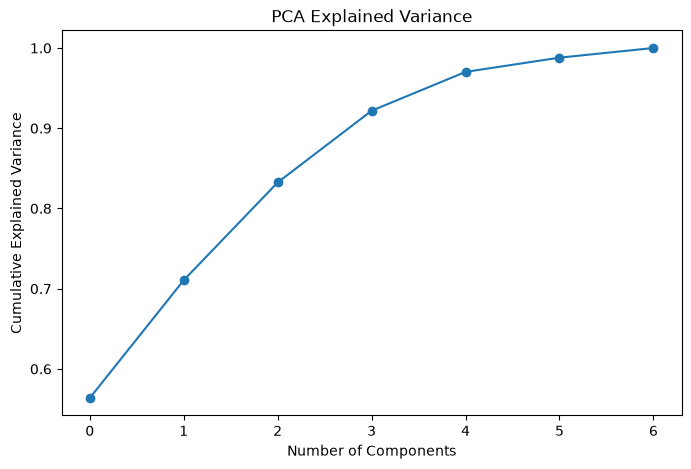

In [116]:
pca = PCA()

pca_data = pca.fit_transform(scaled_data)

plt.figure(figsize=(8,5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.show()

Figure presents the cumulative explained variance from PCA. The first two principal components captured approximately 83% of the total variance, indicating that they retained most of the information contained in the original healthcare indicators. As the explained variance increased only gradually after two components, PCA with two components was considered sufficient for data visualization and clustering analysis

In [69]:
pca = PCA(n_components=2)

pca_results = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_results,
    columns=['PC1','PC2']
)

# K-Means Clustering

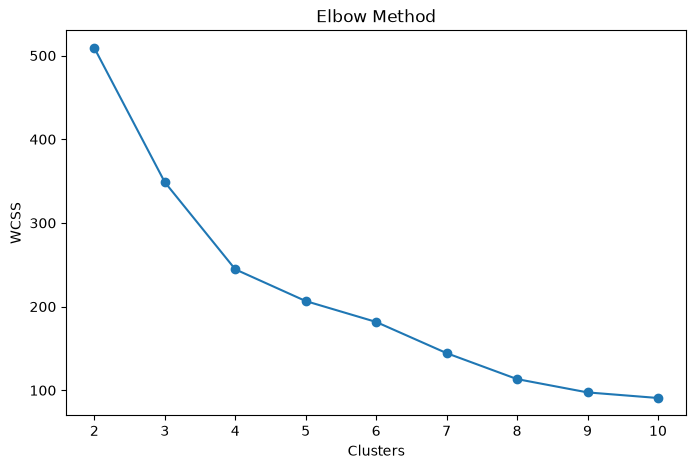

In [70]:
wcss = []

for i in range(2,11):

    km = KMeans(
        n_clusters=i,
        random_state=42
    )

    km.fit(pca_df)

    wcss.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), wcss, marker='o')
plt.xlabel("Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

Figure shows the Elbow Method used to identify the optimal number of clusters for K-Means clustering. The WCSS decreases as the number of clusters increases; however, a noticeable elbow occurs at k = 4, after which the rate of improvement becomes much smaller. This indicates that four clusters provide the best trade-off between cluster quality and model complexity. Therefore, a four-cluster solution was selected to categorize countries according to their healthcare system characteristics.

In [71]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

clusters = kmeans.fit_predict(pca_df)

pca_df['Cluster'] = clusters

cluster_by_country = pd.Series(clusters, index=country_names)
latest_df['Cluster'] = latest_df['country_name'].map(cluster_by_country)

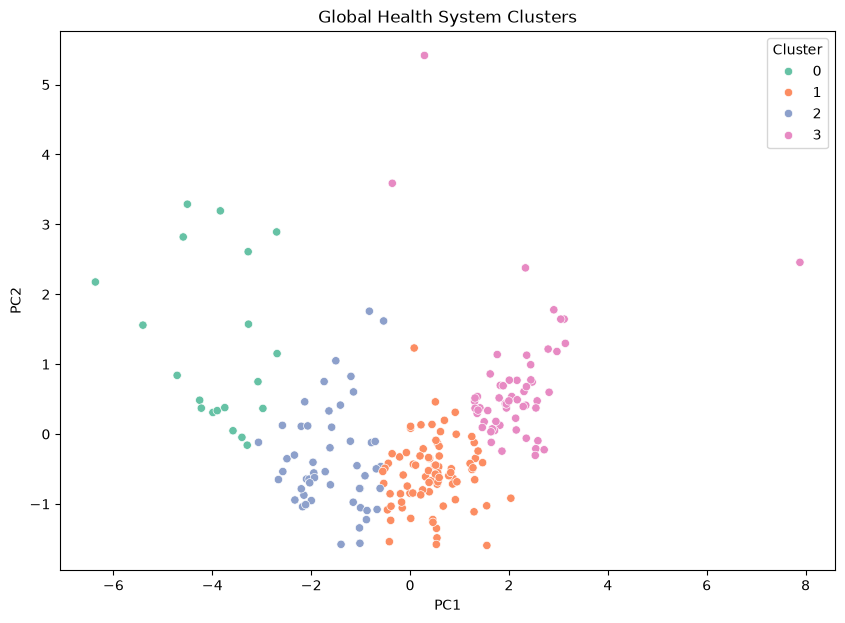

In [72]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=pca_df,
    palette='Set2'
)

plt.title("Global Health System Clusters")
plt.show()

Figure illustrates the four healthcare system clusters identified using K-Means clustering after dimensionality reduction with PCA. Countries within the same cluster share similar health and socioeconomic characteristics, while countries in different clusters exhibit distinct healthcare profiles. The clear separation between groups indicates that the clustering process successfully identified meaningful patterns within the data. These findings highlight global disparities in health system performance and provide a framework for comparing countries with similar healthcare conditions.

In [73]:
country_data.assign(Cluster=cluster_by_country).groupby('Cluster')[selected_features].mean()

indicator_code,life_expectancy,maternal_mortality,under5_mortality,health_expenditure_pct_gdp,gdp_per_capita,physicians_per_1000,hospital_beds_per_1000
Cluster,,,,,,,
0,60.845750,505.850000,80.140000,6.889176,978.820695,0.162400,0.674500
1,76.327419,40.759259,13.817901,5.893150,20418.801275,2.024383,2.574691
2,68.154981,170.653846,36.936538,5.248899,3140.708970,0.460981,1.416154
3,79.862053,19.344828,5.431034,9.276969,48265.306987,4.015207,5.111034


The clustering analysis identified four distinct categories of healthcare systems. Cluster 0 represents Vulnerable Health Systems, characterized by poor health outcomes, limited healthcare resources, and low levels of economic development. Cluster 2 represents Developing Health Systems, where countries are experiencing healthcare improvements but continue to face significant health and infrastructure challenges.

Cluster 1 represents Emerging Health Systems, comprising countries with relatively strong healthcare performance, moderate healthcare resources, and improving population health outcomes. Cluster 3 represents High-Performing Health Systems, which exhibit the highest life expectancy, lowest mortality levels, strongest healthcare infrastructure, and highest levels of economic development.

Overall, the clusters reveal a clear progression from vulnerable healthcare systems (Cluster 0) to highly developed healthcare systems (Cluster 3), highlighting the strong relationship between healthcare investment, economic prosperity, healthcare resource availability, and population health outcomes.


In [74]:
# silhouette score
silhouette_avg = silhouette_score(pca_df[['PC1', 'PC2']], clusters)

print("Silhouette Score:", round(silhouette_avg, 3))

Silhouette Score: 0.427


The Silhouette Score of 0.427 indicates moderate cluster quality, suggesting that countries within the same cluster are relatively similar while remaining reasonably distinct from countries in other clusters. This supports the validity of the four-cluster solution and confirms that meaningful patterns were identified within the global health indicators data

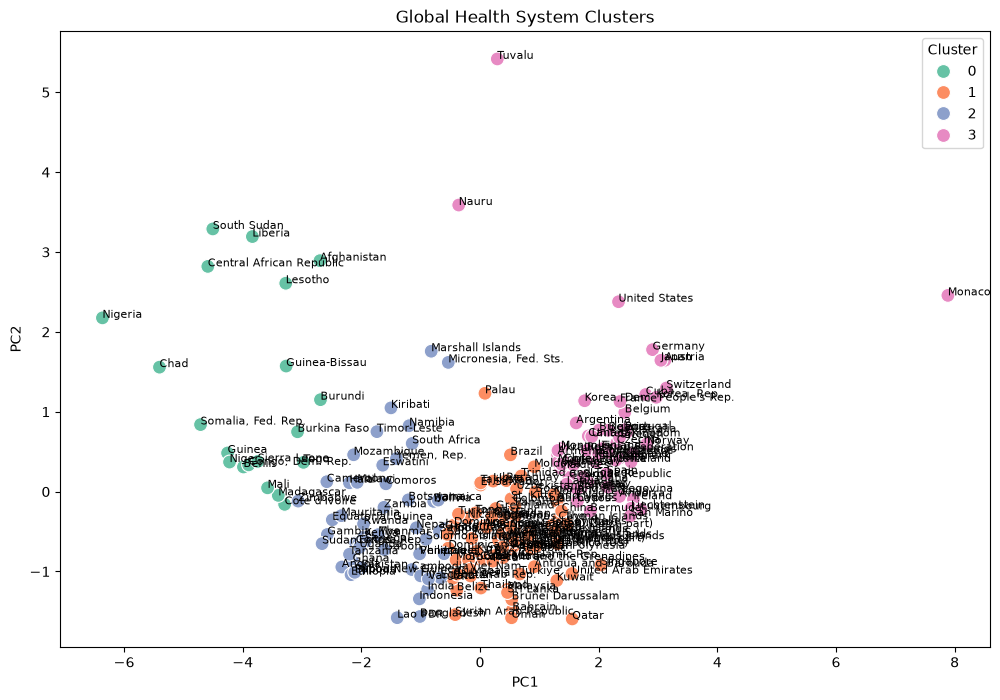

In [75]:
plt.figure(figsize=(12,8))

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=pca_df,
    palette='Set2',
    s=100
)

for i, country in enumerate(country_names):
    plt.text(
        pca_df.iloc[i]['PC1'],
        pca_df.iloc[i]['PC2'],
        country,
        fontsize=8
    )

plt.title("Global Health System Clusters")
plt.show()

The clustering analysis identified four distinct categories of healthcare systems. Cluster 0 (Vulnerable Health Systems) includes countries such as Nigeria and Chad, which experience poor health outcomes and limited healthcare resources. Cluster 2 (Developing Health Systems) includes countries such as Kenya and India that are progressing in healthcare development. Cluster 1 (Emerging Health Systems) includes countries such as Brazil and China, which exhibit relatively strong healthcare performance and improving infrastructure. Cluster 3 (High-Performing Health Systems) includes countries such as Germany, Switzerland, and Japan, which achieve the best health outcomes and possess the most advanced healthcare systems.

# Time Series Forecasting

In [77]:
prophet_df = health_df.loc[
    health_df['country_name'].eq('Kenya'),
    ['year', 'life_expectancy']
].copy()

prophet_df.columns = ['ds', 'y']
prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'].astype(int).astype(str),
    format='%Y'
)

prophet_df.columns = ['ds','y']

prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'],
    format='%Y'
)

In [87]:
model = Prophet()


model.fit(prophet_df)
future = model.make_future_dataframe(
    periods=6,
    freq='YE'
)

10:04:29 - cmdstanpy - INFO - Chain [1] start processing
10:04:30 - cmdstanpy - INFO - Chain [1] done processing


Text(0.5, 1.0, 'Life Expectancy Forecast')

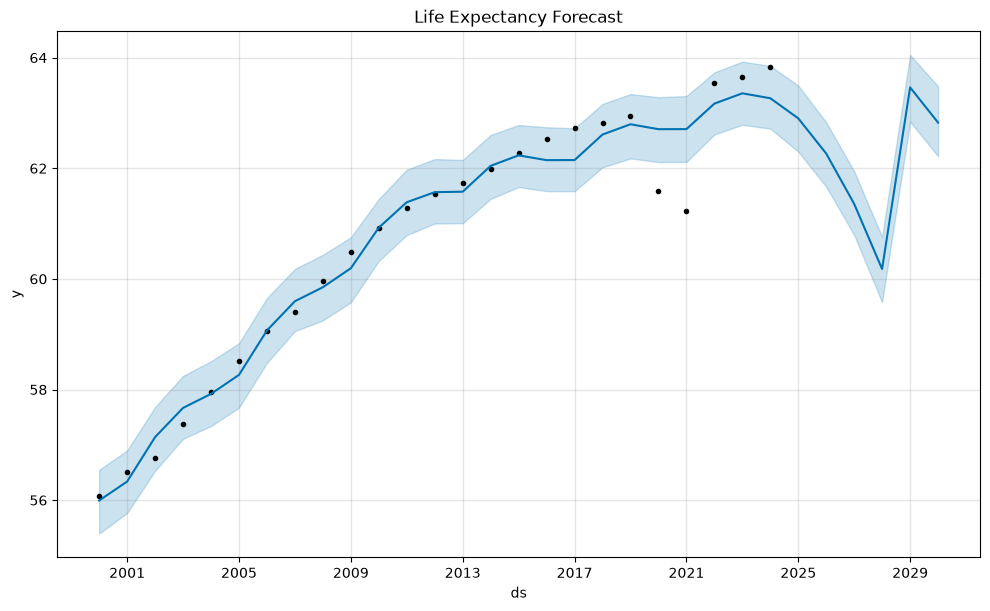

In [88]:
forecast = model.predict(future)
fig = model.plot(forecast)


plt.title(
    "Life Expectancy Forecast"
)

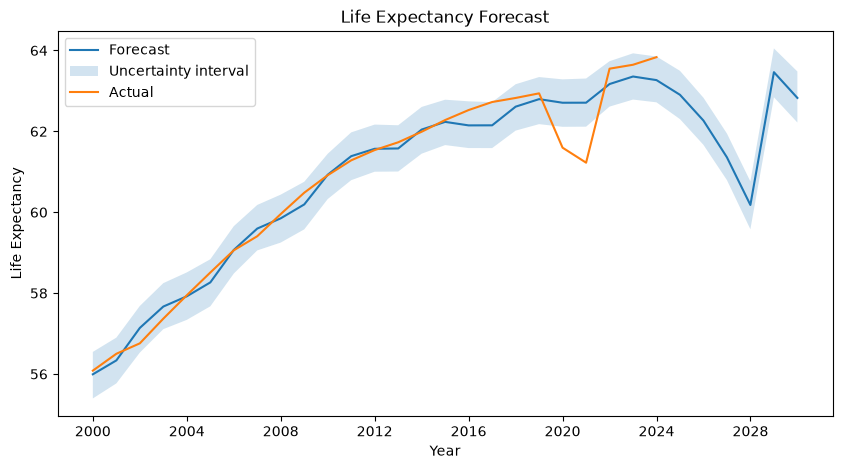

In [89]:
plt.figure(figsize=(10, 5))
plt.plot(forecast['ds'], forecast['yhat'], label='Forecast')
plt.fill_between(
    forecast['ds'],
    forecast['yhat_lower'],
    forecast['yhat_upper'],
    alpha=0.2,
    label='Uncertainty interval'
)
plt.plot(prophet_df['ds'], prophet_df['y'], label='Actual')

plt.title("Life Expectancy Forecast")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.legend()
plt.show()



Figure  presents life expectancy forecasts for the period 2000-2030. The Prophet model closely follows the observed life expectancy values from 2000 to 2024, successfully capturing the overall upward trend in life expectancy over time. While minor deviations are observed around 2020-2021, the model accurately reflects the long-term pattern of growth. The forecasts for 2025-2030 suggest that life expectancy is expected to remain stable and continue increasing gradually, indicating sustained improvements in population health outcomes.

In [91]:
train = prophet_df[:-5]
test = prophet_df[-5:]

model = Prophet()
model.fit(train)

future = model.make_future_dataframe(
    periods=5,
    freq='YE'
)

forecast = model.predict(future)

predictions = forecast['yhat'].tail(5).values
actuals = test['y'].values

10:05:56 - cmdstanpy - INFO - Chain [1] start processing
10:06:16 - cmdstanpy - INFO - Chain [1] done processing


In [92]:
actual = prophet_df['y']

predicted = forecast.iloc[
    :len(actual)
]['yhat']

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

mae = mean_absolute_error(
    actual,
    predicted
)

print("RMSE:", rmse)
print("MAE:", mae)


RMSE: 1.5504136196529492
MAE: 0.6156279779278117


# LSTM Forecasting

In [93]:
series = prophet_df['y'].to_numpy(dtype=float)

In [94]:
scaler = MinMaxScaler()

scaled = scaler.fit_transform(
    series.reshape(-1,1)
)

In [95]:
def create_sequences(
    data,
    window=3
):

    X = []
    y = []

    for i in range(
        len(data)-window
    ):

        X.append(
            data[i:i+window]
        )

        y.append(
            data[i+window]
        )

    return np.array(X), np.array(y)

X,y = create_sequences(
    scaled,
    3
)

In [96]:
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

In [97]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(3,1)
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    LSTM(32)
)

model.add(
    Dense(1)
)

model.compile(
    optimizer='adam',
    loss='mse'
)

history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=4,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - loss: 0.4727
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3522
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2341
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1179
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0293 
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0224
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0290
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0096
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0125 
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0131
Epoch 11/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0122
Epoch 12/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0127
Epoch 13/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0098
Epoch 14/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0119
Epoch 15/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0131
Epoch 16/100
6/6

In [98]:
predictions = model.predict(X)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(y)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 516ms/step


In [100]:
last_sequence = scaled[-3:]

future_predictions = []

for _ in range(6):

    pred = model.predict(
        last_sequence.reshape(1,3,1),
        verbose=0
    )

    future_predictions.append(
        pred[0,0]
    )

    last_sequence = np.append(
        last_sequence[1:],
        pred
    )

In [101]:
rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

mae = mean_absolute_error(
    actual,
    predictions
)

print("LSTM RMSE:", rmse)
print("LSTM MAE:", mae)

LSTM RMSE: 0.6584425596988349
LSTM MAE: 0.390381999622691


The LSTM model achieved an MAE of 0.390 and an RMSE of 0.658, indicating high forecasting accuracy and minimal prediction errors. The low error values show that the model's predictions closely matched the observed life expectancy values

# Model Comparison

In [ ]:
# Model Comparison
prophet_actual = test['y'].to_numpy()
prophet_predictions = forecast['yhat'].tail(len(test)).to_numpy()

prophet_mae = mean_absolute_error(prophet_actual, prophet_predictions)
prophet_rmse = np.sqrt(mean_squared_error(prophet_actual, prophet_predictions))

lstm_actual = np.asarray(actual).ravel()
lstm_predictions = np.asarray(predictions).ravel()

lstm_mae = mean_absolute_error(lstm_actual, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(lstm_actual, lstm_predictions))


print(comparison)

     Model       MAE      RMSE
0  Prophet  3.078106  3.466830
1     LSTM  0.390382  0.658443


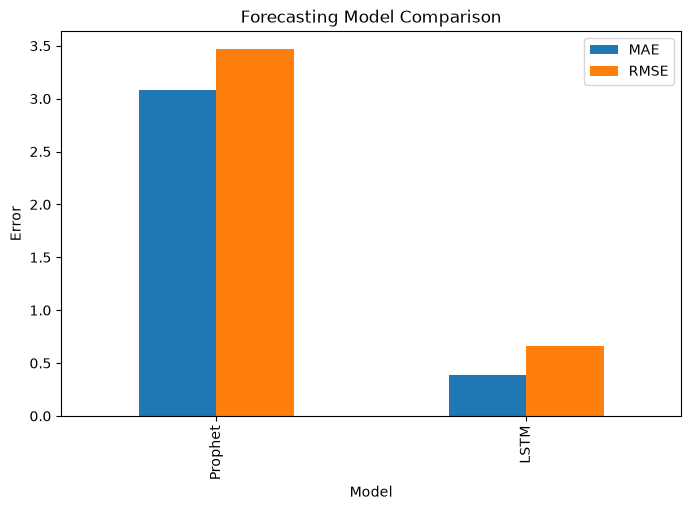

In [ ]:
# Visualisation of Model Comparison
comparison.set_index('Model')[['MAE','RMSE']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Forecasting Model Comparison')
plt.ylabel('Error')
plt.show()

This figure presents a comparison of Prophet and LSTM forecasting models based on MAE and RMSE metrics. The LSTM model achieved substantially lower error values (MAE = 0.39, RMSE = 0.66) compared to Prophet (MAE = 3.08, RMSE = 3.47), demonstrating superior forecasting performance. These findings suggest that LSTM was more effective at capturing the temporal patterns within the life expectancy data and was therefore selected as the best-performing forecasting model for the study.

# Suitable Model -LSTM

In [ ]:
# LSTM Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))
r2 = r2_score(actual, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.390381999622691
RMSE: 0.6584425596988349
R²: 0.8692220816979495


The LSTM model achieved an MAE of 0.390, RMSE of 0.658, and R² of 0.869. The low MAE and RMSE values indicate high forecasting accuracy, while the R² score shows that 86.9% of the variability in life expectancy was captured by the model. These results demonstrate that the LSTM model effectively learned the temporal patterns in the data and provided reliable forecasts for future life expectancy trends.

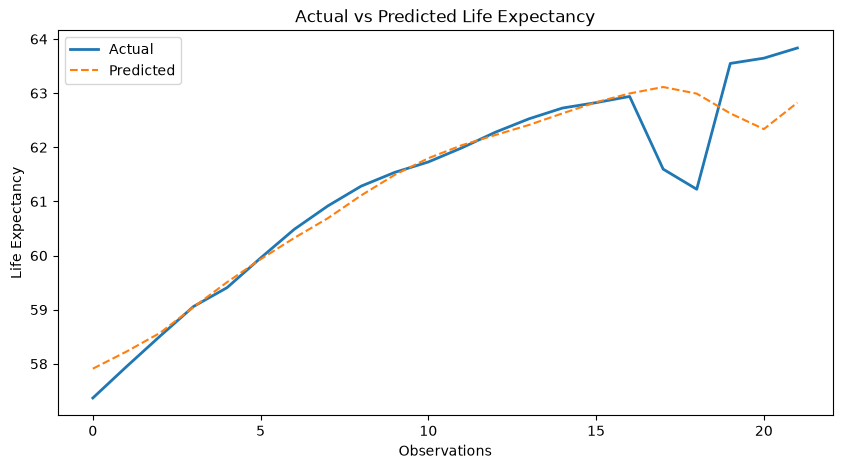

In [ ]:
# Visualisation of Actual vs Predicted Life Expectancy
plt.figure(figsize=(10,5))

plt.plot(
    actual,
    label='Actual',
    linewidth=2
)

plt.plot(
    predictions,
    label='Predicted',
    linestyle='--'
)

plt.title('Actual vs Predicted Life Expectancy')
plt.xlabel('Observations')
plt.ylabel('Life Expectancy')
plt.legend()

plt.show()

This figure shows comparison the actual and predicted life expectancy values generated by the LSTM model. The predicted values closely follow the actual trend throughout the observation period, indicating that the model successfully learned the temporal patterns within the data. Although small deviations are visible during periods of sudden fluctuation, the overall alignment between the two curves demonstrates strong predictive performance. These findings, together with the low forecasting errors (MAE = 0.390, RMSE = 0.658) and high explanatory power (R² = 0.869), confirm the effectiveness of the LSTM model for forecasting life expectancy trends.

In [ ]:
# Future Forecasting 
last_year = prophet_df['ds'].dt.year.max()

future_years = [
    last_year + i
    for i in range(1,7)
]

future_forecast = pd.DataFrame({
    'Year': future_years,
    'Predicted_Life_Expectancy': np.asarray(future_predictions).reshape(-1)
})

print(future_forecast)

   Year  Predicted_Life_Expectancy
0  2025                   0.991170
1  2026                   1.000897
2  2027                   1.009067
3  2028                   1.009397
4  2029                   1.015179
5  2030                   1.019117


In [ ]:
#inverse transform the future predictions to get the actual life expectancy values
future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1,1)
)

In [ ]:
# flatten the future predictions to create a 1D array
future_forecast = pd.DataFrame({
    'Year': future_years,
    'Predicted_Life_Expectancy':
    future_predictions.flatten()
})

print(future_forecast)

   Year  Predicted_Life_Expectancy
0  2025                  63.765564
1  2026                  63.840950
2  2027                  63.904270
3  2028                  63.906826
4  2029                  63.951630
5  2030                  63.982155


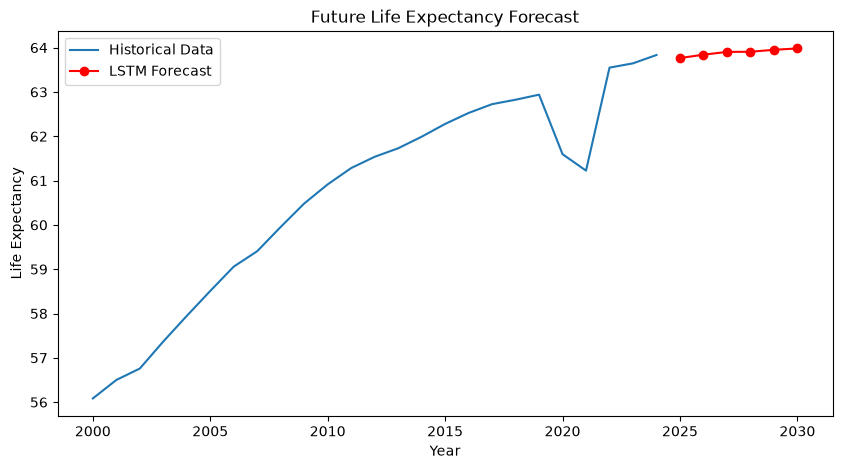

In [115]:
# Visualisation of Future Life Expectancy Forecast
plt.figure(figsize=(10,5))

plt.plot(
    prophet_df['ds'].dt.year,
    prophet_df['y'],
    label='Historical Data'
)

plt.plot(
    future_years,
    future_predictions,
    marker='o',
    color='red',
    label='LSTM Forecast'
)

plt.title(
    'Future Life Expectancy Forecast'
)

plt.xlabel('Year')
plt.ylabel('Life Expectancy')

plt.legend()
plt.show()

This figure illustrates the historical life expectancy data and the future forecasts generated by the LSTM model. The results indicate a continued upward trend in life expectancy between 2025 and 2030, increasing from approximately 63.8 years to 64.0 years. The smooth forecast pattern suggests stable improvements in health outcomes over time, with no significant declines anticipated during the forecast period. These findings demonstrate the model's expectation of sustained progress in population health and healthcare system performance.